In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("data.csv")
df

,Student,Maths,Physics,Chemistry,Biology
0,S1,90,85,88,80
1,S2,85,82,84,78
2,S3,40,45,42,50
3,S4,45,48,40,52
4,S5,95,90,92,88
5,S6,35,38,40,42
6,S7,75,72,78,70
7,S8,70,68,72,65
8,S9,55,58,52,60
9,S10,60,62,58,65


In [3]:
X = df[['Maths', 'Physics', 'Chemistry', 'Biology']]

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled)

[[ 1.234662    1.19704886  1.19530969  1.08936168]
 [ 0.9877296   1.01926933  0.99098325  0.94411345]
 [-1.234662   -1.17334492 -1.15444441 -1.08936168]
 [-0.9877296  -0.99556539 -1.25660763 -0.94411345]
 [ 1.48159439  1.49334808  1.39963614  1.67035457]
 [-1.48159439 -1.58816383 -1.25660763 -1.67035457]
 [ 0.4938648   0.42667088  0.68449359  0.36312056]
 [ 0.2469324   0.1896315   0.37800392  0.        ]
 [-0.4938648  -0.40296694 -0.6436283  -0.36312056]
 [-0.2469324  -0.16592756 -0.33713863  0.        ]]


In [5]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(X_pca)

[[ 2.35845267  0.07463228]
 [ 1.97116653  0.02765169]
 [-2.32623588 -0.04860063]
 [-2.09126931 -0.22768146]
 [ 3.02236823 -0.18086911]
 [-2.99891581  0.30280392]
 [ 0.98356441  0.23809809]
 [ 0.40719037  0.26700469]
 [-0.95134762 -0.21206644]
 [-0.37497358 -0.24097303]]


In [6]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Student'] = df['Student']

print(pca_df)

        PC1       PC2 Student
0  2.358453  0.074632      S1
1  1.971167  0.027652      S2
2 -2.326236 -0.048601      S3
3 -2.091269 -0.227681      S4
4  3.022368 -0.180869      S5
5 -2.998916  0.302804      S6
6  0.983564  0.238098      S7
7  0.407190  0.267005      S8
8 -0.951348 -0.212066      S9
9 -0.374974 -0.240973     S10


In [7]:
print("Explained Variance Ratio:")

print(pca.explained_variance_ratio_)

print("Total Variance Preserved:")

print(sum(pca.explained_variance_ratio_) * 100)

Explained Variance Ratio:
[0.98849133 0.01039904]
Total Variance Preserved:
99.8890375957832


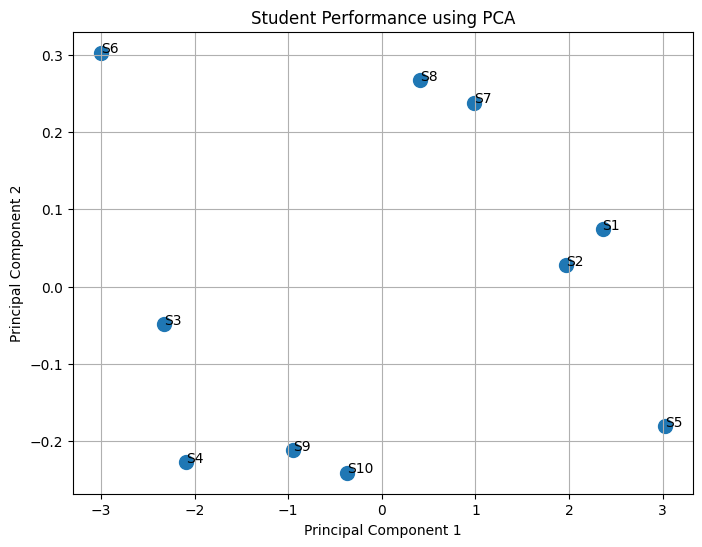

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=100
)

for i, student in enumerate(pca_df['Student']):
    plt.annotate(
        student,
        (pca_df['PC1'][i], pca_df['PC2'][i])
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.title('Student Performance using PCA')

plt.grid()
plt.show()

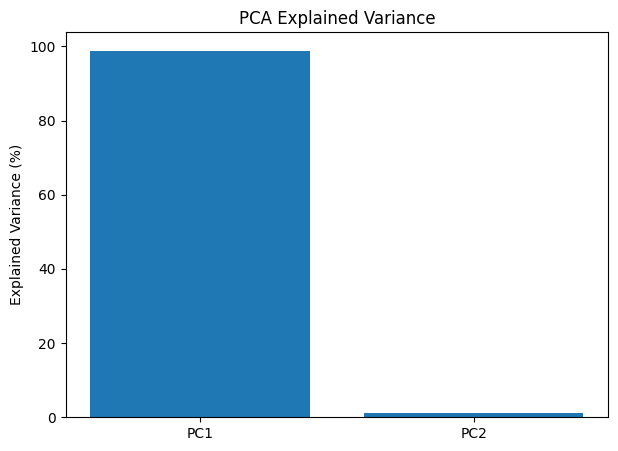

In [9]:
variance = pca.explained_variance_ratio_

plt.figure(figsize=(7, 5))

plt.bar(
    ['PC1', 'PC2'],
    variance * 100
)

plt.ylabel('Explained Variance (%)')
plt.title('PCA Explained Variance')

plt.show()